# Expansion Data 
This code will recreate figure panels as well as plot individual dendrites and determine summary values of key variables
>>  mean diam <br>
>>  length <br>
>>  distance <br>
>>  resistance <br>


In [1]:
import matplotlib.pyplot as plt
plt.rc("axes.spines", top=False, right=False)

import seaborn as sns
import pandas as pd
import numpy as np
from scipy import stats

from tqdm import tqdm

###changes default of autoreloader to continually reload (2) rather than only on restart
####good for debuggin but does slow code as it is continully reloading modules
#%load_ext autoreload
#%autoreload 2

import os
import glob

plot_path="../output/plots"
mypath = plot_path

import sys
import os
sys.path.append("../src")
from Branch_analysis import branch_dsc, update_DSCs, update_compartments
from Summary_analysis import summary_dsc, summary_compt, avgCDF
from plots import plot_dsc

## Load dendritic diameter data
Set location of repo data (root folder) sets the paths for each expanded dendrite analysed

In [2]:
from pathlib import Path

root = Path('../repo_data/')
if not root.exists():
    raise FileNotFoundError(f"Root folder '{root}' not found.")

# Initialize the ExM data dictionary
ExMdata = {}

# Helper function to add dendrites
def add_dendrite(data, dendrite_name, subfolder, filename, ex_factor, res):
    folder_path = root / subfolder / 'tables'
    data[dendrite_name] = {
        'path': folder_path / filename,
        'file': filename,
        'ex_factor': ex_factor,
        'res': res
    }

# Add dendrites with helper function
add_dendrite(ExMdata, 'dendrite1', 'ExM/2016_07_07/branch1', '2016_07_07_slice4_left_branch1_Local Diameter.csv', 4.1, 1)
# Uncomment if needed after verification
# add_dendrite(ExMdata, 'dendrite2', 'ExM/2016_07_07/branch2', '2016_07_07_slice4_left_branch2_Local Diameter.csv', 4.1, 1)
add_dendrite(ExMdata, 'dendrite3', 'ExM/2016_07_07/branch3', '2016_07_07_slice4_left_branch3_Local Diameter.csv', 4.1, 1)
add_dendrite(ExMdata, 'dendrite4', 'ExM/2019_05_04/branch4', '2019_05_04_slice3_side1_branch4_localDiameter.csv', 4.1, 1)

add_dendrite(ExMdata, 'C1_02_cell1_d2', 'ExM/2020_06_08/T1_02', '20210201_DG-T1_AF488-02_neuron01_8bit_1000-3000_dend2 - Local Diameter.csv', 3.8, 0.173)
add_dendrite(ExMdata, 'C1_03_cell2_d2', 'ExM/2020_06_08/T1_03', '20210201_dg-t1_af488-03_decon-Resolution Level 1_8bit_480-2600_dend2 - Local Diameter.csv', 3.8, 0.173)
add_dendrite(ExMdata, 'C1_03_cell2_d3', 'ExM/2020_06_08/T1_03', '20210201_dg-t1_af488-03_decon-Resolution Level 1_8bit_480-2600_dend3 - Local Diameter.csv', 3.8, 0.173)

# Optionally, print or log ExMdata to verify paths and parameters
print(ExMdata)

{'dendrite1': {'path': PosixPath('../repo_data/ExM/2016_07_07/branch1/tables/2016_07_07_slice4_left_branch1_Local Diameter.csv'), 'file': '2016_07_07_slice4_left_branch1_Local Diameter.csv', 'ex_factor': 4.1, 'res': 1}, 'dendrite3': {'path': PosixPath('../repo_data/ExM/2016_07_07/branch3/tables/2016_07_07_slice4_left_branch3_Local Diameter.csv'), 'file': '2016_07_07_slice4_left_branch3_Local Diameter.csv', 'ex_factor': 4.1, 'res': 1}, 'dendrite4': {'path': PosixPath('../repo_data/ExM/2019_05_04/branch4/tables/2019_05_04_slice3_side1_branch4_localDiameter.csv'), 'file': '2019_05_04_slice3_side1_branch4_localDiameter.csv', 'ex_factor': 4.1, 'res': 1}, 'C1_02_cell1_d2': {'path': PosixPath('../repo_data/ExM/2020_06_08/T1_02/tables/20210201_DG-T1_AF488-02_neuron01_8bit_1000-3000_dend2 - Local Diameter.csv'), 'file': '20210201_DG-T1_AF488-02_neuron01_8bit_1000-3000_dend2 - Local Diameter.csv', 'ex_factor': 3.8, 'res': 0.173}, 'C1_03_cell2_d2': {'path': PosixPath('../repo_data/ExM/2020_06_08/

Load and analyse each dendrite .csv files

In [3]:
dataSet=ExMdata
for name, dendrite in tqdm(dataSet.items()):
    #print(name)
    #print(data[name]['path'])
    
    file_path = dendrite['path']#+dendrite['file']
    dataSet[name] = branch_dsc(file_path, dataSet[name]['res'], dataSet[name]['ex_factor'])

100%|███████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 40.68it/s]


Manually adjust DSC 
<br> add DSCs missing as diam increses slighlty in the middle <br>
<br> remove false postives

In [4]:
dendrite = ExMdata['C1_03_cell2_d3']
DSC=dendrite['data'][3947:4047].copy() # makes a copy to work on
DSC.diam*=1/dendrite['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/dendrite['ex_factor']
DSC.length*=dendrite['res']/dendrite['ex_factor']
DSC.pt_distance*=dendrite['res']/dendrite['ex_factor']
dendrite['DSCs'].append(DSC) # add the changes back to the copy of the original data

update_DSCs(dendrite)
update_compartments(dendrite)

dendrite = ExMdata['C1_03_cell2_d2']
del dendrite['DSCs'][2] #the auto detected DSC is too long past the DSC -shortened

update_DSCs(dendrite)
update_compartments(dendrite)


dendrite = ExMdata['dendrite1']
del dendrite['DSCs'][11] #noisey false positives
del dendrite['DSCs'][10] #noisey false positives
del dendrite['DSCs'][9] #noisey false positives
del dendrite['DSCs'][8] #noisey false positives
del dendrite['DSCs'][7] #
del dendrite['DSCs'][2] #false positive

update_DSCs(dendrite)
update_compartments(dendrite)

In [5]:
from Branch_analysis import add_branch, FindBranch
add_branch(ExMdata)
FindBranch(ExMdata)


### Create figure panels for Fig1 
Fig1g DSC mean diameter
Fig1h DSC lenght
Fig1j DSC distance
select paramtert to plot [mean, lenght, distance]

distance mean = 206.6139200582526 +- sem 18.42151726435988 count 35


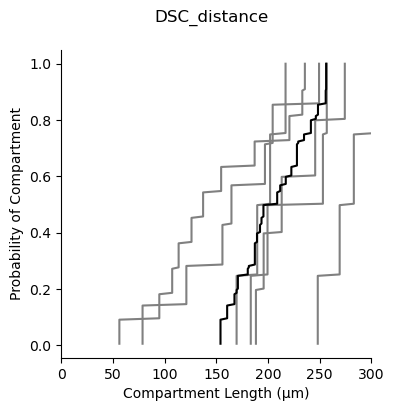

In [6]:
#select property to plot [mean, lenght, distance]
parameter='distance'
df= summary_dsc(ExMdata, parameter)

# plot the cumulative histogram for each dendrite
n_bins=200
n, bins, patches = plt.hist(df.transpose(), n_bins, density=True, histtype='step', cumulative=True)
# Close the plot to suppress it
plt.close()

avg_df, bins = avgCDF(df, patches, n_bins, n)

fig, ax = plt.subplots(figsize=(4, 4))
fig.suptitle("DSC_"+parameter)
ax.plot(avg_df.iloc[:, :-1], bins, color='grey')
ax.plot(avg_df.iloc[:, len(avg_df.columns)-1], bins, color='black')
ax.set_xlabel("Compartment Length (µm)")  # µm is used for the micron symbol
ax.set_ylabel("Probability of Compartment")

ax.set_xlim([0,300])
print(f"{parameter} mean = {df.transpose().mean().mean()} +- sem {df.transpose().mean().sem()} count {df.melt().count().value}")

fig.savefig(mypath+'/ExM_DSC_'+parameter+'_Cumulative.svg', bbox_inches = 'tight')

### Create figure panels for Fig. 1 
Fig. 1j Compartment length

distance mean = 17.22498988477291 +- sem 1.5446653001734683 count 35


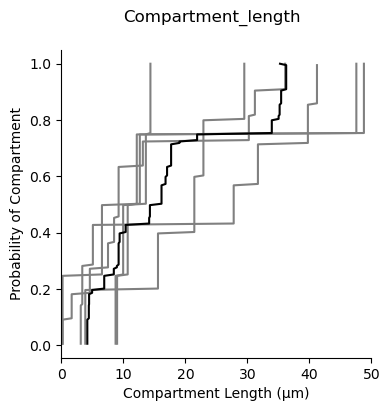

In [7]:
df= summary_compt(ExMdata, 'length')

# plot the cumulative histogram for each dendrite
n_bins=200
n, bins, patches = plt.hist(df.transpose(), n_bins, density=True, histtype='step', cumulative=True)
# Close the plot to suppress it
plt.close()

avg_df, bins = avgCDF(df, patches, n_bins, n)

fig, ax = plt.subplots(figsize=(4, 4))
fig.suptitle("Compartment_length")
ax.plot(avg_df.iloc[:, :-1], bins, color='grey')
ax.plot(avg_df.iloc[:, len(avg_df.columns)-1], bins, color='black')
ax.set_xlabel("Compartment Length (µm)")  # µm is used for the micron symbol
ax.set_ylabel("Probability of Compartment")

ax.set_xlim([0,50])
print(f"{parameter} mean = {df.transpose().mean().mean()} +- sem {df.transpose().mean().sem()} count {df.melt().count().value}")
fig.savefig(mypath+'/ExM_compartment_length_Cumulative.svg', bbox_inches = 'tight')

### Select dendrite and branch to analyse
Example dendrite shown in Supplemental Fig. 1b 

In [8]:
#data, dendrite branch
dend_name= 'C1_03_cell2_d3'  #'dendrite3' #'dendrite1' 'dendrite4' #'C1_02_cell1_d2'   #'C1_03_cell2_d2' 'C1_03_cell2_d3'
branchNo= 3
#branchs=dendbranch_dic[dend_name]
df=ExMdata[dend_name]['DSC_properties']

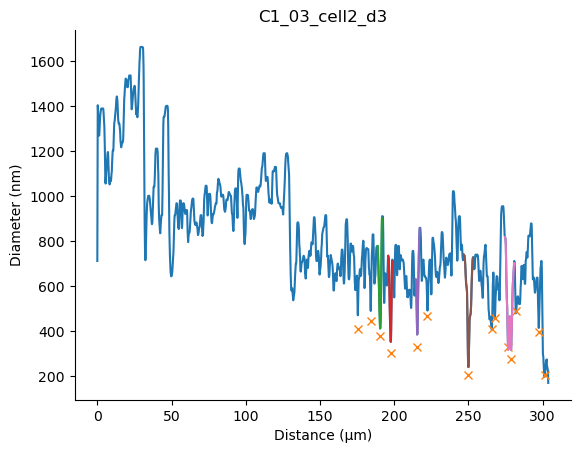

In [9]:
fig, ax = plot_dsc(ExMdata[dend_name],dend_name, corr=1)

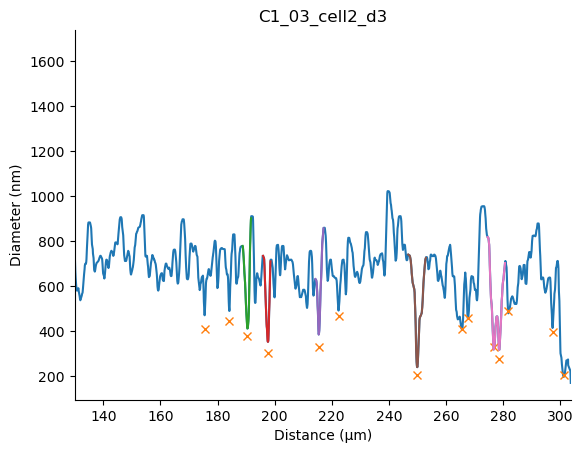

In [10]:
#sets start and end points of branch
strt = ExMdata[dend_name]['branchNo'][branchNo][1]

if branchNo + 1 < len(ExMdata[dend_name]['branchNo']) and ExMdata[dend_name]['branchNo'][branchNo+1] in ExMdata[dend_name]['branchNo']:
    end = ExMdata[dend_name]['branchNo'][branchNo+1][1]
else:
    end = (ExMdata[dend_name]['data']['length'].iloc[-1] * 
           ExMdata[dend_name]['res'] / 
           ExMdata[dend_name]['ex_factor'])

ax.set_xlim(strt, end)
fig

### Create figure panels for supplemental Fig. 1
Example dendrite shown in Supplemental Fig. 1b 

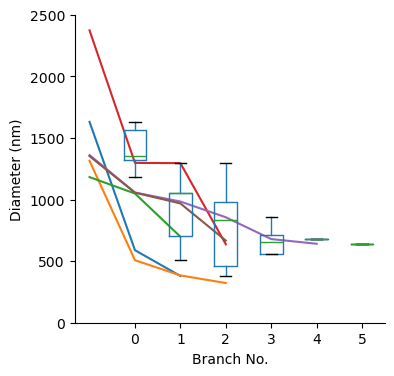

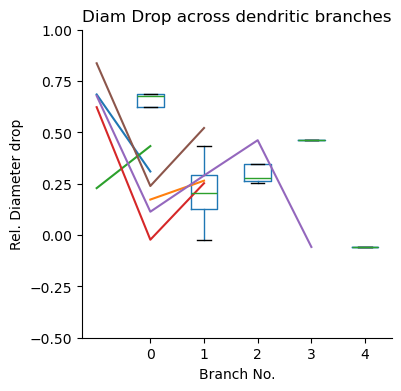

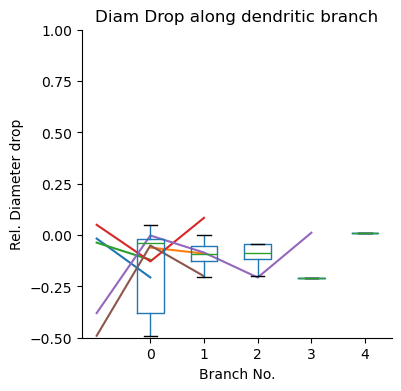

In [11]:
from plots import branch_figs
df=branch_figs(ExMdata, plot_path)

In [17]:
DropAcross=[]
DropAlong=[]
for dendrite, data in ExMdata.items():
    #print(dendrite)
    DropAcross.append(np.mean((data['branch_info']['dropAcross'])))
    DropAlong.append(np.mean((data['branch_info']['dropAlong'])))

# Calculate mean and SEM, omitting NaN values
mean_drop_across = np.nanmean(DropAcross)
sem_drop_across  = stats.sem(DropAcross, nan_policy='omit')
mean_drop_along  = np.nanmean(DropAlong)
sem_drop_along   = stats.sem(DropAlong, nan_policy='omit')

print(f'Average drop across dendrite {mean_drop_across}, SEM {sem_drop_across}')
print(f'Average drop along dendrite {mean_drop_along}, SEM {sem_drop_along}')


Average drop across dendrite 0.3883233070403354, SEM 0.0524575914251438
Average drop along dendrite -0.11366000920389711, SEM 0.04046423068541762


### Calculate Resistances for DSCs and Dendritic Shafts

Resistance values are estimated from morphology, as described in [Tonnesen et al. 2014](https://pubmed.ncbi.nlm.nih.gov/24657968/), using the following formula:

$$
R_{\text{morph}} = \frac{\rho \cdot L}{A}
$$

where:

- $(\rho)$ is the resistivity, with a value of $(181 \, \Omega \cdot \text{cm})$
- $(L)$ is the length of the segment
- $(A)$ is the cross-sectional area of the segment

In [18]:
from Branch_analysis import resistance_branch, compile_resistances

dendbranch_dic={'dendrite1': [1,2],'dendrite3':[1,2,3], 'dendrite4':[2], 'C1_02_cell1_d2':[3], 'C1_03_cell2_d2':[5],'C1_03_cell2_d3':[3]}

resistance_branch(dendbranch_dic, ExMdata)
Rdend_data, Rmorph_data, length_data = compile_resistances(ExMdata)

Plot resistances

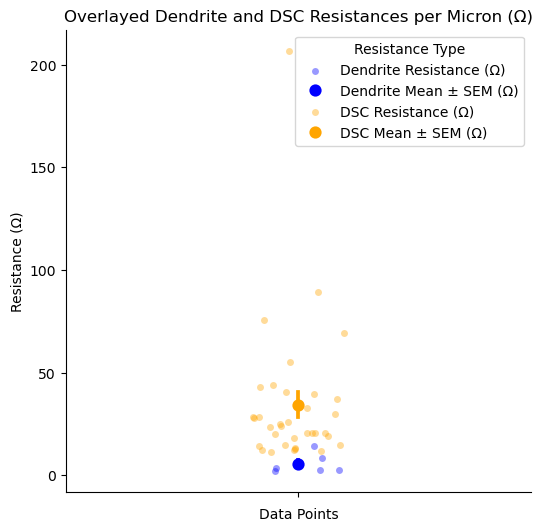

Dendrite resistance per micron: Mean = resistance    5.562759
dtype: float64 Ω, SEM = resistance    1.929532
dtype: float64 Ω, Count = resistance    6
dtype: int64
DSC resistance per micron: Mean = resistance    34.371693
dtype: float64 Ω, SEM = resistance    5.968993
dtype: float64 Ω, Count = dendrite      35
resistance    35
dtype: int64
Sum of DSC resistance per dendrite: Mean = resistance    259.728778
dtype: float64 Ω, SEM = resistance    113.787012
dtype: float64 Ω, Count = resistance    6
dtype: int64


In [23]:
# Prepare the data for dendrite resistance
df_dend = pd.concat(Rdend_data)
df_dend = df_dend.reset_index(level=0)
df_dend = df_dend.rename(columns={'level_0': 'dendrite'})
grp_df_dend = df_dend.groupby('dendrite').mean(numeric_only=True)

# Prepare the data for DSC resistance
df_dsc = pd.DataFrame(Rmorph_data, columns=['dendrite', 'resistance'])
length_df = pd.DataFrame(length_data, columns=['dendrite', 'length'])

# Create the plot
fig, ax = plt.subplots(figsize=(6, 6))

# Plot dendrite resistance
sns.stripplot(y='resistance', data=grp_df_dend, color='blue', alpha=0.4, label='Dendrite Resistance (Ω)', ax=ax)
sns.pointplot(y='resistance', data=grp_df_dend, color='blue', errorbar='se', linestyle='none', label='Dendrite Mean ± SEM (Ω)', ax=ax)

# Plot DSC resistance
sns.stripplot(y='resistance', data=df_dsc, color='orange', alpha=0.4, label='DSC Resistance (Ω)', ax=ax)
sns.pointplot(y='resistance', data=df_dsc, color='orange', errorbar='se', linestyle='none', label='DSC Mean ± SEM (Ω)', ax=ax)

# Set labels, title, and legend
ax.set_ylabel("Resistance (Ω)")
ax.set_xlabel("Data Points")
ax.legend(title="Resistance Type")
plt.title("Overlayed Dendrite and DSC Resistances per Micron (Ω)")

# Show plot
plt.show()

# Print dendrite resistance statistics
print(f"Dendrite resistance per micron: Mean = {grp_df_dend.mean(numeric_only=True)} Ω, SEM = {grp_df_dend.sem(numeric_only=True)} Ω, Count = {grp_df_dend.count()}")

# Print DSC resistance statistics
print(f"DSC resistance per micron: Mean = {df_dsc.mean(numeric_only=True)} Ω, SEM = {df_dsc.sem(numeric_only=True)} Ω, Count = {df_dsc.count()}")

# Calculate total resistance for DSC
ResisTotal = {'resistance': length_df.length * df_dsc.resistance, 'dendrite': df_dsc.dendrite}
df_total = pd.DataFrame(ResisTotal)
grp_df_total = df_total.groupby('dendrite').sum(numeric_only=True)
print(f"Sum of DSC resistance per dendrite: Mean = {grp_df_total.mean(numeric_only=True)} Ω, SEM = {grp_df_total.sem(numeric_only=True)} Ω, Count = {grp_df_total.count()}")